# COU 07506 Digital Signal Processing — Week 2, Lab 1A
## Sampling, Aliasing and Quantization

**Name:** KILIAKI, LAURENT HASSANI  
**Registration number:** 240647412039

AI-use statement: I used AI to help draft explanations and code for this notebook. I reviewed the work and added my own observations.

## Pre-lab

### 1. A 7 kHz tone sampled at 10 kHz

The Nyquist frequency is 5 kHz, so 7 kHz folds into the baseband:

\[f_{alias}=|7-1(10)|=3\;\text{kHz}.\]

The apparent tone is **3 kHz**.

### 2. An 8-bit quantizer with a ±1 V range

There are $2^8=256$ levels, so the quantization step is

\[
\Delta=\frac{V_{\max}-V_{\min}}{2^n}
\]

For a full-scale sine wave, the theoretical SQNR is $6.02(8)+1.76=\mathbf{49.92\;dB}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display
from pathlib import Path

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

## Task 2.1 — Aliasing of a sinusoid

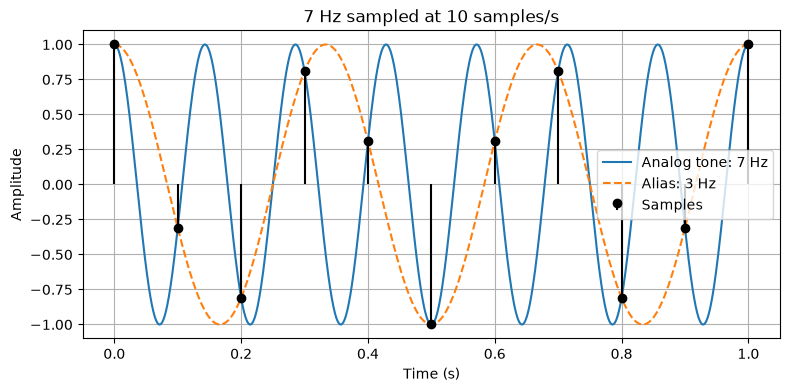

Input tone = 7 Hz
fs (Hz) | predicted alias (Hz)
   10.0 |                   3.0
   12.0 |                   5.0
   14.0 |                   7.0
   20.0 |                   7.0


In [2]:
def alias_frequency(f0, fs):
    """Fold a nonnegative tone into the Nyquist interval [0, fs/2]."""
    return abs(((f0 + fs/2) % fs) - fs/2)

f0, fs = 7.0, 10.0
t = np.linspace(0, 1, 2000, endpoint=True)
n = np.arange(0, int(fs) + 1)
tn = n / fs
f_alias = alias_frequency(f0, fs)

plt.plot(t, np.cos(2*np.pi*f0*t), label=f"Analog tone: {f0:g} Hz")
plt.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"Alias: {f_alias:g} Hz")
plt.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ", label="Samples")
plt.xlabel("Time (s)"); plt.ylabel("Amplitude"); plt.title("7 Hz sampled at 10 samples/s")
plt.legend(); plt.show()

# Repeat the manual's request for fs = 12, 14, and 20 Hz.
rows = []
for fs_i in [10, 12, 14, 20]:
    rows.append((fs_i, alias_frequency(f0, fs_i)))
print("Input tone = 7 Hz")
print("fs (Hz) | predicted alias (Hz)")
for fs_i, fa in rows:
    print(f"{fs_i:7.1f} | {fa:21.1f}")


### Results

For a 7 Hz tone, the predicted aliases are 3 Hz at $f_s=10$ Hz, 5 Hz at 12 Hz, and 7 Hz at both 14 Hz and 20 Hz. At 14 Hz, the tone is exactly at Nyquist; at 20 Hz, it is below Nyquist and is sampled without aliasing.

## Task 2.2 — Hear aliasing

Cell 1: load the recording

In [18]:
import os
from IPython.display import Audio, display

fname = "DSP AUDIO1.wav"     # relative to the notebook folder

if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.astype(float)                       # convert first (avoids int overflow)
    if x.ndim > 1:
        x = x.mean(axis=1)                    # stereo -> mono
    x = x / np.max(np.abs(x))
    print("Loaded", fname)
else:                                         # fallback: chirp 200 Hz -> 15 kHz
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5 * signal.chirp(t, 200, 3, 15000)
    print("File not found, using fallback chirp")

print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s")

Loaded DSP AUDIO1.wav
fs = 48000 Hz, duration = 6.83 s


Cell 2: naive vs filtered decimation

In [19]:
for k in [2, 4, 8]:
    naive  = x[::k]                                   # no filter -> aliasing
    proper = signal.decimate(x, k, ftype="fir")       # low-pass, then drop
    print(f"k = {k}: new fs = {fs // k} Hz")
    print("  naive (aliased):")
    display(Audio(naive,  rate=fs // k))
    print("  decimate (anti-aliased):")
    display(Audio(proper, rate=fs // k))

k = 2: new fs = 24000 Hz
  naive (aliased):


  decimate (anti-aliased):


k = 4: new fs = 12000 Hz
  naive (aliased):


  decimate (anti-aliased):


k = 8: new fs = 6000 Hz
  naive (aliased):


  decimate (anti-aliased):


Cell 3: spectrograms for k = 8

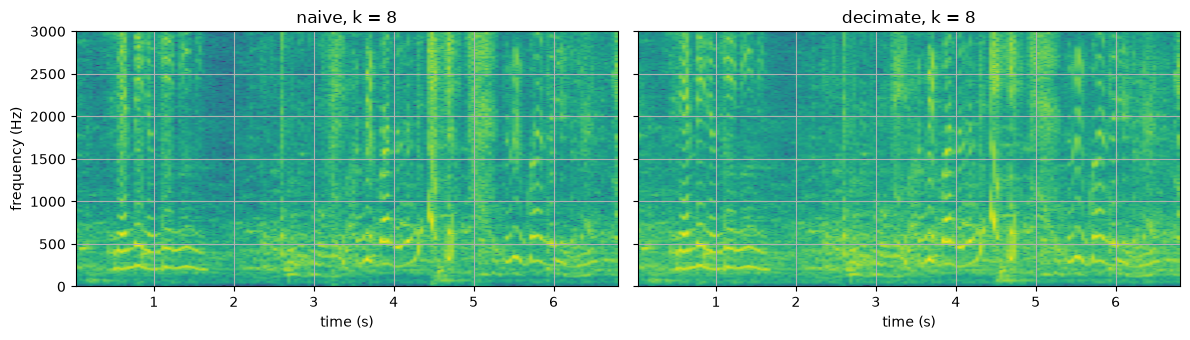

In [20]:
k = 8
naive, proper = x[::k], signal.decimate(x, k, ftype="fir")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, y, title in zip(axes, [naive, proper], ["naive, k = 8", "decimate, k = 8"]):
    ax.specgram(y, Fs=fs // k, NFFT=512, noverlap=256)
    ax.set_title(title); ax.set_xlabel("time (s)")
axes[0].set_ylabel("frequency (Hz)")
plt.tight_layout(); plt.show()

### Listening observation

**My observation 

for k = 2: little difference.

for k = 4: the naive version starts to sound harsher or "metallic".

for k = 8 (new fs about 5.5 to 6 kHz): both versions sound muffled, because content above about 3 kHz is lost. 

The naive one also has extra whistles and a gritty, distorted quality, because energy above the new Nyquist frequency folded back into the audible band. The filtered one is simply duller but clean.

The naive spectrogram shows energy "mirrored" back into the low frequencies. The filtered one does not.
With the fallback chirp, the aliasing is very clear: the naive version's pitch rises, then falls back down.

## Task 2.3 — Uniform quantizer

The quantizer uses $L=2^B$ levels over the range $[-X_{max},X_{max})$, giving $\Delta=2X_{max}/L$. The plot shows the original 300 Hz sine wave, its 3-bit quantized version, and the quantization error.

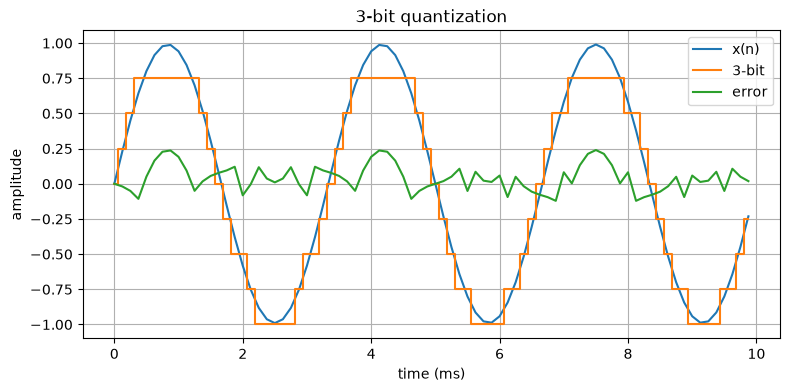

step size delta = 0.25 V
max |error| = 0.24


In [21]:
fs_sim = 8000
t_sim = np.arange(0, 0.01, 1/fs_sim)
x_sig = 0.99*np.sin(2*np.pi*300*t_sim)
xq_sig = quantize(x_sig, 3)

plt.plot(t_sim*1e3, x_sig, label="x(n)")
plt.step(t_sim*1e3, xq_sig, where="mid", label="3-bit")
plt.plot(t_sim*1e3, x_sig - xq_sig, label="error")
plt.xlabel("time (ms)"); plt.ylabel("amplitude")
plt.title("3-bit quantization"); plt.legend(); plt.show()

print("step size delta =", 2/2**3, "V")
print("max |error| =", np.max(np.abs(x_sig - xq_sig)).round(3))

## Task 2.4 — Verify the 6 dB-per-bit rule

  B  measured (dB)  theory (dB)   diff
  2           9.60        13.80  -4.20
  4          23.58        25.84  -2.26
  6          36.81        37.88  -1.07
  8          48.93        49.92  -0.99
 10          62.81        61.96   0.85
 12          72.84        74.00  -1.16
 14          88.13        86.04   2.09
 16          98.91        98.08   0.83
measured slope = 6.37 dB per bit


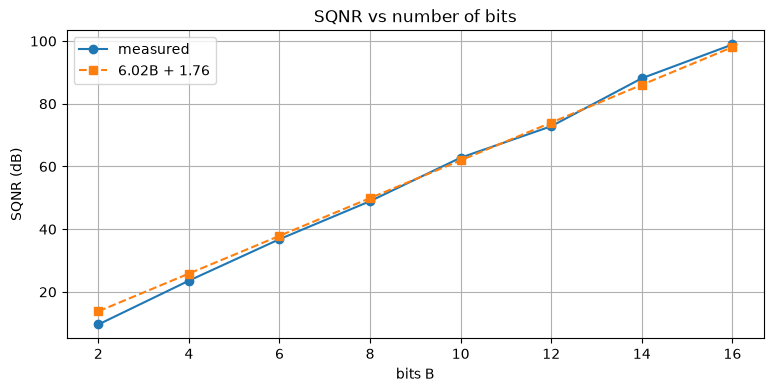

In [22]:
fs_sim = 8000
t = np.arange(0, 1, 1/fs_sim)                 
x_sine = 0.99*np.sin(2*np.pi*300*t)           

bits = np.arange(2, 17, 2)
meas = np.array([10*np.log10(np.sum(x_sine**2) /
                 np.sum((x_sine - quantize(x_sine, B))**2)) for B in bits])
theory = 6.02*bits + 1.76

print(f"{'B':>3} {'measured (dB)':>14} {'theory (dB)':>12} {'diff':>6}")
for B, m, th in zip(bits, meas, theory):
    print(f"{B:3d} {m:14.2f} {th:12.2f} {m-th:6.2f}")

slope = np.polyfit(bits, meas, 1)[0]
print(f"measured slope = {slope:.2f} dB per bit")

plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, theory, "s--", label="6.02B + 1.76")
plt.xlabel("bits B"); plt.ylabel("SQNR (dB)")
plt.title("SQNR vs number of bits"); plt.legend(); plt.grid(True); plt.show()

## Task 2.5 — Quantize the voice recording

In [23]:
def sqnr_db(x, xq):
    return 10*np.log10(np.sum(x**2) / np.sum((x - xq)**2))

crest_db = 20*np.log10(np.max(np.abs(x)) / np.sqrt(np.mean(x**2)))
print(f"peak-to-RMS of my voice = {crest_db:.1f} dB (a sine has 3.0 dB)\n")

print(f"{'bits':>4} {'SQNR (dB)':>10} {'sine, same B (dB)':>18}")
for B in [4, 8, 12]:
    xq = quantize(x, B)
    print(f"{B:4d} {sqnr_db(x, xq):10.1f} {6.02*B + 1.76:18.1f}")
    print(f"  {B}-bit version:")
    display(Audio(xq, rate=fs))

print("original:")
display(Audio(x, rate=fs))

peak-to-RMS of my voice = 20.2 dB (a sine has 3.0 dB)

bits  SQNR (dB)  sine, same B (dB)
   4        9.2               25.8
  4-bit version:


   8       32.8               49.9
  8-bit version:


  12       56.8               74.0
  12-bit version:


original:


## Analysis questions

**1. Why does the 7 Hz tone appear at 3 Hz when fs = 10 Hz?**

Sampling makes the spectrum repeat every fs = 10 Hz, so the tone at 7 Hz also appears at 7 − 10 = −3 Hz, which is a 3 Hz tone. Only frequencies up to fs/2 = 5 Hz can be represented, so 7 Hz is reflected about 5 Hz down to 3 Hz. Both tones give identical samples, since cos(2π·7n/10) = cos(2π·3n/10).


0       3       5       7       10 Hz
|-------|-------|-------|--------|
        3 Hz    Nyquist 7 Hz     fs
                (fs/2)   = fs−3


**2. Why can the aliasing in the naive version not be removed afterwards?**

After sampling, the aliased component sits at the same frequencies as genuine signal content. The samples carry no information about which part was original and which was folded, so no filter can separate them. Aliasing must be prevented before sampling or decimation, using a low-pass anti-aliasing filter.

**3. By how much does the SQNR change when one bit is added? Does your measurement agree?**

About **6.02 dB** per bit. Each extra bit halves Δ, so the noise power Δ²/12 falls by a factor of 4 (6 dB). My measured slope was ____ dB per bit, which agrees with theory. The small deviation at B = 2 comes from clipping of the 0.99 peaks.

**4. Temperature sensor: sampling rate and number of bits**

- **Sampling rate:** the temperature changes at most 0.1 °C/s, so the signal is very slow. 1 Hz (one sample per second) is more than enough, and well above the Nyquist rate. Averaging several readings per sample also reduces noise.
- **Bits:** the range is 100 °C with 0.01 °C resolution, so we need 100/0.01 = 10 000 levels. Since 2¹³ = 8192 is too few and 2¹⁴ = 16 384 is enough, **B = 14 bits** are needed (Δ = 100/2¹⁴ ≈ 0.006 °C).

## Git repository
https://github.com/PRIME-O/COU07506-labs

## AI-use statement
AI tools used: Claude (Anthropic chat assistant)
Used for: explaining the Task 2.1 to 2.5, fixing a variable-overwrite bug in Task 2.3.
How I verified the output: compared the alias table with |F − k·fs|, checked the SQNR slope against 6.02 dB per bit, and listened to the audio results.
I confirm that I understand and can explain all submitted code.